# Bank Customer Churn Analysis

A corrected probability-based comparison of logistic regression, a modest decision-tree search, and a prior baseline on the original 10,000-row teaching benchmark.

See the repository README, dataset notice, and methodology-change log before execution.

## Reproducible setup

Acquire the documented benchmark into the ignored `data/` directory. This notebook does not install packages or make network requests. All saved results are generated by the corrected source module.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src' / 'analyze.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'analyze.py').is_file():
    raise RuntimeError('Run from the repository root or its notebooks directory')
sys.path.insert(0, str(ROOT / 'src'))
from analyze import run
DATA = ROOT / 'data' / 'Churn_Modelling.csv'
if not DATA.is_file():
    raise FileNotFoundError('Acquire the documented benchmark; see data/README.md')


## Corrected analysis

The source module defines the feature contract, preparation, evaluation, and plots. Displayed values below are computed from the local input, with its SHA-256 recorded in `results/summary.json`.

In [2]:
summary, *_ = run(DATA, ROOT / 'results')
summary


Out[0]: 
{'task': 'Educational bank-customer churn benchmark; no connection to an employer/client dataset',
 'input_file': 'Churn_Modelling.csv',
 'input_sha256': '80341b2fb83322455f0870fe65a8ce99703f2a2d59d57d432dda3c02ec93f563',
 'rows': 10000,
 'feature_names': ['CreditScore',
  'Age',
  'Tenure',
  'Balance',
  'NumOfProducts',
  'HasCrCard',
  'IsActiveMember',
  'EstimatedSalary',
  'Geography',
  'Gender'],
 'excluded_identifiers_and_artifacts': ['#',
  'RowNumber',
  'CustomerId',
  'Surname',
  'NumOfProducts_int'],
 'train_rows': 8000,
 'test_rows': 2000,
 'split_seed': 0,
 'train_churn_prevalence': 0.20375,
 'test_churn_prevalence': 0.2035,
 'cv': 'Five stratified training-only folds; entire preprocessing/model Pipeline searched by probability-based average precision',
 'test_use': 'One final fixed 20% holdout; no threshold tuning or model selection on this holdout',
 'models': {'Prior baseline': {'accuracy': 0.7965,
   'balanced_accuracy': 0.5,
   'positive_precision': 0.0,

## Compact result tables

These are aggregated outputs. Raw benchmark records and original notebook outputs are not included in the publication.

,model,accuracy,balanced_accuracy,positive_precision,positive_recall,positive_f1,roc_auc,average_precision
0,Prior baseline,0.7965,0.500000,0.000000,0.000000,0.000000,0.500000,0.203500
1,Logistic regression,0.8125,0.566751,0.673913,0.152334,0.248497,0.760010,0.486131
2,Decision tree,0.8480,0.707023,0.684588,0.469287,0.556851,0.837695,0.649752


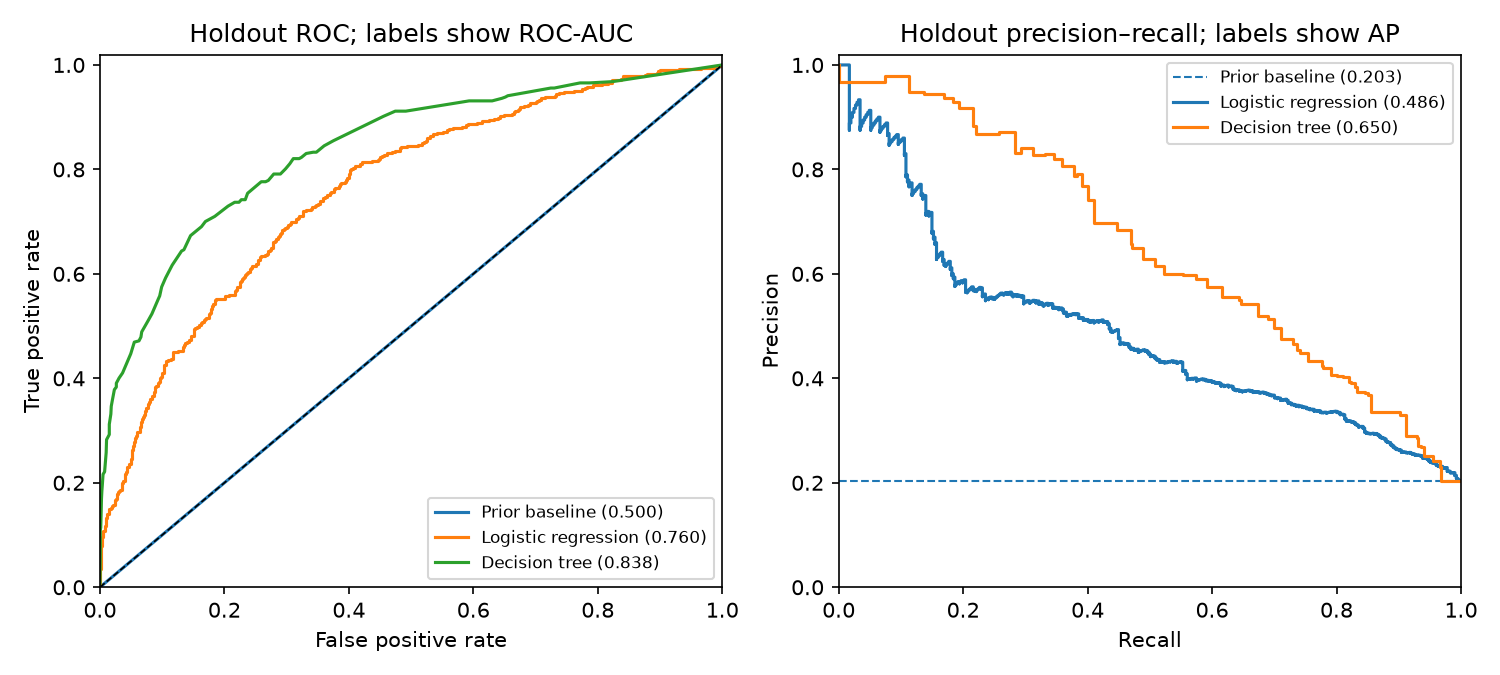

In [3]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(ROOT / 'results' / 'test_metrics.csv'))
display(Image(filename=str(ROOT / 'results' / 'classification_curves.png')))


## Interpretation boundaries

Average precision and ROC-AUC use probabilities; precision/recall/F1 use a fixed threshold of 0.5. Training-only CV selects hyperparameters. This random benchmark holdout is not a prospective bank deployment, a causal explanation, or an estimated retention benefit.